In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense
 
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

In [28]:
gray_scale = 255
x_train = x_train.astype('float32') / gray_scale
x_test = x_test.astype('float32') / gray_scale
 
print("Feature matrix (x_train):", x_train.shape)
print("Target matrix (y_train):", y_train.shape)
print("Feature matrix (x_test):", x_test.shape)
print("Target matrix (y_test):", y_test.shape)

Feature matrix (x_train): (60000, 28, 28)
Target matrix (y_train): (60000,)
Feature matrix (x_test): (10000, 28, 28)
Target matrix (y_test): (10000,)


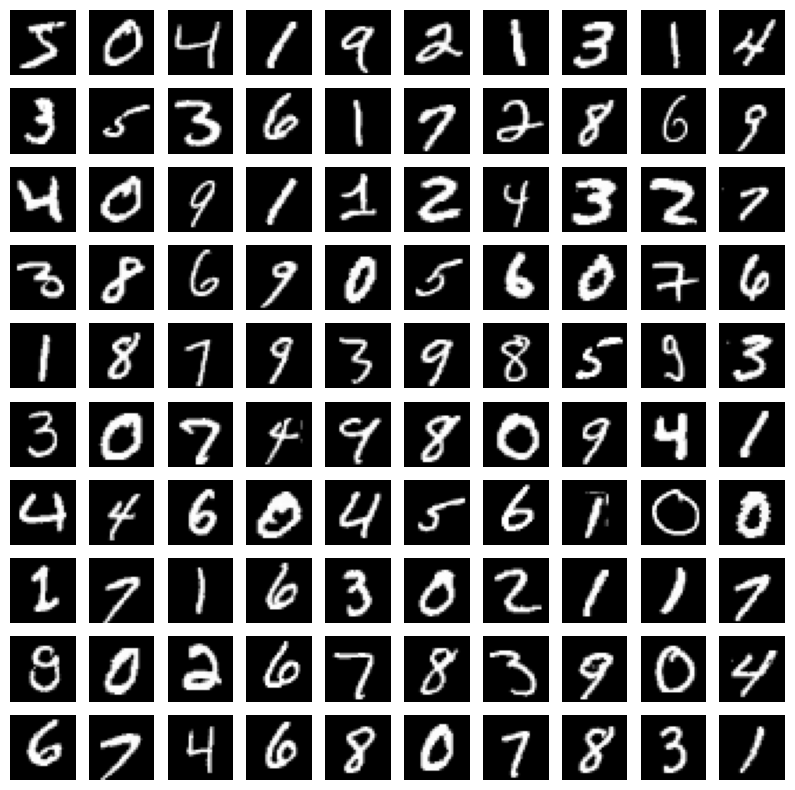

In [29]:
fig, ax = plt.subplots(10, 10, figsize=(10, 10))
k = 0
for i in range(10):
    for j in range(10):
        ax[i][j].imshow(x_train[k], cmap='gray', aspect='auto')
        ax[i][j].axis('off')
        k += 1
plt.show()

In [30]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),                         # 28x28 -> 784
    Dense(256, activation='sigmoid'),  # capa oculta 1
    Dense(128, activation='sigmoid'),  # capa oculta 2
    Dense(10, activation='softmax'),   # salida: 10 clases (0-9)
])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

In [32]:
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=2000,
    validation_split=0.2,
)

Epoch 1/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.1054 - loss: 2.3357 - val_accuracy: 0.0989 - val_loss: 2.3107
Epoch 2/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.1088 - loss: 2.3039 - val_accuracy: 0.1060 - val_loss: 2.3037
Epoch 3/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.1102 - loss: 2.3024 - val_accuracy: 0.1060 - val_loss: 2.3045
Epoch 4/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.1070 - loss: 2.3027 - val_accuracy: 0.1060 - val_loss: 2.3044
Epoch 5/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.1129 - loss: 2.3026 - val_accuracy: 0.0997 - val_loss: 2.3034
Epoch 6/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.1107 - loss: 2.3028 - val_accuracy: 0.1060 - val_loss: 2.3047
Epoch 7/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.1088 - loss: 2.3034 - val_accuracy: 0.0975 - val_loss: 2.3054
Epoch 8/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.1126 - loss: 2.3029 - val_accuracy: 0.1060 - v

In [33]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print("Test loss:", test_loss)
print("Test accuracy:", test_acc)

Test loss: 2.301664113998413
Test accuracy: 0.11349999904632568


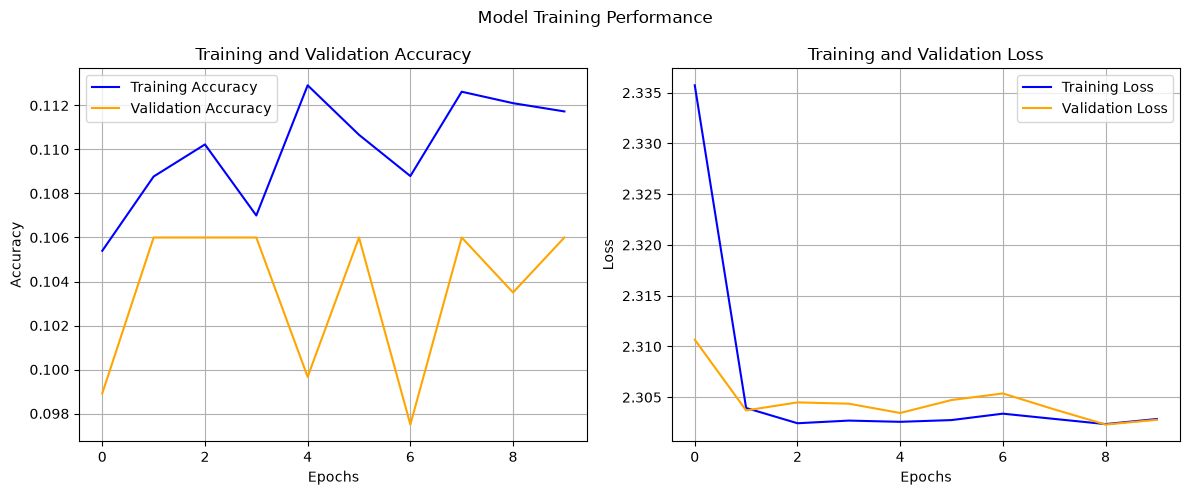

In [34]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy', color='blue')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss', color='blue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.suptitle("Model Training Performance")
plt.tight_layout()
plt.show()

Predicción: 1 | Valor real: 7


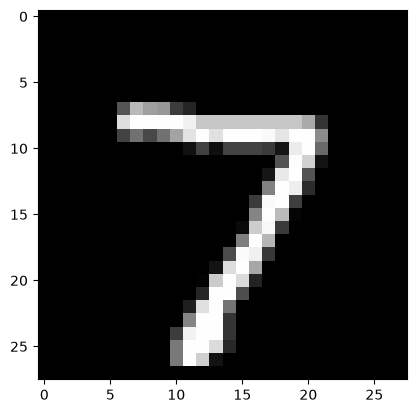

In [36]:
# %% Probar una predicción
idx = 0
pred = model.predict(x_test[idx:idx + 1], verbose=0)
print("Predicción:", np.argmax(pred), "| Valor real:", y_test[idx])
plt.imshow(x_test[idx], cmap='gray')
plt.show()